In [3]:
import pandas as pd
data = pd.read_csv("sample_data_cleaning_project.csv")
print(data)


        Name   Age    Salary  Join_Date Department
0        Pam  25.0   70200.0  1/15/2023         HR
1       Jane   NaN   65000.0   8/1/2022    Finance
2      Alice  22.0   71350.0  5/20/2021         HR
3        Bob  22.0       NaN  1/15/2023         IT
4        Pam  25.0   71250.0  1/15/2023         HR
5       Jade  40.0       NaN  1/15/2023    Finance
6     Joanne  25.0  120000.0  1/16/2023         IT
7        Kim  33.0   71568.0  8/30/2021         HR
8        Sam  40.0       NaN   9/5/2022         IT
9        Eli   NaN   80100.0   3/4/2022         HR
10       Joe  22.0   62000.0  10/9/2022    Finance
11      Anna  36.0   72456.0   4/6/2022         HR
12       Dan  43.0       NaN  1/15/2023         HR
13     Susan  46.0   66000.0   5/3/2022    Finance
14    Pamela   NaN   77421.0   4/2/2023         HR
15      Susy  41.0  126001.0   2/2/2023         IT
16      Ruth  30.0   72114.0   9/5/2022         HR
17       Dan  43.0       NaN   5/3/2022         HR
18    Joanne  25.0  125600.0  1

In [6]:
print("\nMissing Values Count: ")
print(data.isnull().sum())


Missing Values Count: 
Name          0
Age           4
Salary        7
Join_Date     0
Department    0
dtype: int64


In [8]:
data['Age']= data['Age'].fillna(data['Age'].median())
data['Salary']= data['Salary'].fillna(data['Salary'].mean())
data=data.dropna(subset=['Join_Date'])
print(data)

        Name   Age         Salary  Join_Date Department
0        Pam  25.0   70200.000000  1/15/2023         HR
1       Jane  36.0   65000.000000   8/1/2022    Finance
2      Alice  22.0   71350.000000  5/20/2021         HR
3        Bob  22.0  132729.694444  1/15/2023         IT
4        Pam  25.0   71250.000000  1/15/2023         HR
5       Jade  40.0  132729.694444  1/15/2023    Finance
6     Joanne  25.0  120000.000000  1/16/2023         IT
7        Kim  33.0   71568.000000  8/30/2021         HR
8        Sam  40.0  132729.694444   9/5/2022         IT
9        Eli  36.0   80100.000000   3/4/2022         HR
10       Joe  22.0   62000.000000  10/9/2022    Finance
11      Anna  36.0   72456.000000   4/6/2022         HR
12       Dan  43.0  132729.694444  1/15/2023         HR
13     Susan  46.0   66000.000000   5/3/2022    Finance
14    Pamela  36.0   77421.000000   4/2/2023         HR
15      Susy  41.0  126001.000000   2/2/2023         IT
16      Ruth  30.0   72114.000000   9/5/2022    

In [9]:
data=data.apply(lambda x: x.str.strip() if x.dtype == "object" else x)
data=data.apply(lambda x: x.str.lower() if x.dtype == "object" else x)
print(data)

        Name   Age         Salary  Join_Date Department
0        pam  25.0   70200.000000  1/15/2023         hr
1       jane  36.0   65000.000000   8/1/2022    finance
2      alice  22.0   71350.000000  5/20/2021         hr
3        bob  22.0  132729.694444  1/15/2023         it
4        pam  25.0   71250.000000  1/15/2023         hr
5       jade  40.0  132729.694444  1/15/2023    finance
6     joanne  25.0  120000.000000  1/16/2023         it
7        kim  33.0   71568.000000  8/30/2021         hr
8        sam  40.0  132729.694444   9/5/2022         it
9        eli  36.0   80100.000000   3/4/2022         hr
10       joe  22.0   62000.000000  10/9/2022    finance
11      anna  36.0   72456.000000   4/6/2022         hr
12       dan  43.0  132729.694444  1/15/2023         hr
13     susan  46.0   66000.000000   5/3/2022    finance
14    pamela  36.0   77421.000000   4/2/2023         hr
15      susy  41.0  126001.000000   2/2/2023         it
16      ruth  30.0   72114.000000   9/5/2022    

In [10]:
data=data.drop_duplicates(subset=['Name','Age',])
print(data)

        Name   Age         Salary  Join_Date Department
0        pam  25.0   70200.000000  1/15/2023         hr
1       jane  36.0   65000.000000   8/1/2022    finance
2      alice  22.0   71350.000000  5/20/2021         hr
3        bob  22.0  132729.694444  1/15/2023         it
5       jade  40.0  132729.694444  1/15/2023    finance
6     joanne  25.0  120000.000000  1/16/2023         it
7        kim  33.0   71568.000000  8/30/2021         hr
8        sam  40.0  132729.694444   9/5/2022         it
9        eli  36.0   80100.000000   3/4/2022         hr
10       joe  22.0   62000.000000  10/9/2022    finance
11      anna  36.0   72456.000000   4/6/2022         hr
12       dan  43.0  132729.694444  1/15/2023         hr
13     susan  46.0   66000.000000   5/3/2022    finance
14    pamela  36.0   77421.000000   4/2/2023         hr
15      susy  41.0  126001.000000   2/2/2023         it
16      ruth  30.0   72114.000000   9/5/2022         hr
19     clark  44.0   76982.000000  1/28/2023    

In [11]:
print(data.duplicated().sum())

0


In [14]:
Q1=data['Salary'].quantile(0.25)
Q3=data['Salary'].quantile(0.75)
IQR=Q3-Q1

data=data[(data['Salary']>=Q1-1.5*IQR)& (data['Salary']<=Q3+1.5*IQR)]
print(data)

        Name   Age   Salary  Join_Date Department
0        pam  25.0  70200.0  1/15/2023         hr
1       jane  36.0  65000.0   8/1/2022    finance
2      alice  22.0  71350.0  5/20/2021         hr
7        kim  33.0  71568.0  8/30/2021         hr
9        eli  36.0  80100.0   3/4/2022         hr
10       joe  22.0  62000.0  10/9/2022    finance
11      anna  36.0  72456.0   4/6/2022         hr
13     susan  46.0  66000.0   5/3/2022    finance
14    pamela  36.0  77421.0   4/2/2023         hr
16      ruth  30.0  72114.0   9/5/2022         hr
19     clark  44.0  76982.0  1/28/2023         hr
20    alissa  36.0  77421.0  10/5/2022         hr
22   anthony  30.0  61000.0   8/6/2021    finance
23       eli  21.0  77421.0   3/4/2022         hr
24      tony  36.0  66200.0  5/18/2023    finance
26  samantha  50.0  77421.0  1/15/2023         hr
27    amanda  28.0  66100.0  8/23/2021    finance
32     penny  44.0  77421.0   9/4/2022         hr
33     jimmy  38.0  65000.0  10/3/2024         hr


In [15]:
data['Join_Date']=pd.to_datetime(data['Join_Date'])

print(data)

        Name   Age   Salary  Join_Date Department
0        pam  25.0  70200.0 2023-01-15         hr
1       jane  36.0  65000.0 2022-08-01    finance
2      alice  22.0  71350.0 2021-05-20         hr
7        kim  33.0  71568.0 2021-08-30         hr
9        eli  36.0  80100.0 2022-03-04         hr
10       joe  22.0  62000.0 2022-10-09    finance
11      anna  36.0  72456.0 2022-04-06         hr
13     susan  46.0  66000.0 2022-05-03    finance
14    pamela  36.0  77421.0 2023-04-02         hr
16      ruth  30.0  72114.0 2022-09-05         hr
19     clark  44.0  76982.0 2023-01-28         hr
20    alissa  36.0  77421.0 2022-10-05         hr
22   anthony  30.0  61000.0 2021-08-06    finance
23       eli  21.0  77421.0 2022-03-04         hr
24      tony  36.0  66200.0 2023-05-18    finance
26  samantha  50.0  77421.0 2023-01-15         hr
27    amanda  28.0  66100.0 2021-08-23    finance
32     penny  44.0  77421.0 2022-09-04         hr
33     jimmy  38.0  65000.0 2024-10-03         hr


In [16]:
data= pd.get_dummies(data, columns=['Department'], drop_first=True)
binary_columns = [col for col in data.columns if col.startswith('Department_')]
data[binary_columns] = data[binary_columns].astype(int)
print(data)

        Name   Age   Salary  Join_Date  Department_hr  Department_it
0        pam  25.0  70200.0 2023-01-15              1              0
1       jane  36.0  65000.0 2022-08-01              0              0
2      alice  22.0  71350.0 2021-05-20              1              0
7        kim  33.0  71568.0 2021-08-30              1              0
9        eli  36.0  80100.0 2022-03-04              1              0
10       joe  22.0  62000.0 2022-10-09              0              0
11      anna  36.0  72456.0 2022-04-06              1              0
13     susan  46.0  66000.0 2022-05-03              0              0
14    pamela  36.0  77421.0 2023-04-02              1              0
16      ruth  30.0  72114.0 2022-09-05              1              0
19     clark  44.0  76982.0 2023-01-28              1              0
20    alissa  36.0  77421.0 2022-10-05              1              0
22   anthony  30.0  61000.0 2021-08-06              0              0
23       eli  21.0  77421.0 2022-0

In [17]:
data.to_csv("cleaned_data.csv", index=False)

In [18]:
import matplotlib.pyplot as plt
data=pd.read_csv("cleaned_data.csv")
print(data.head())

    Name   Age   Salary   Join_Date  Department_hr  Department_it
0    pam  25.0  70200.0  2023-01-15              1              0
1   jane  36.0  65000.0  2022-08-01              0              0
2  alice  22.0  71350.0  2021-05-20              1              0
3    kim  33.0  71568.0  2021-08-30              1              0
4    eli  36.0  80100.0  2022-03-04              1              0


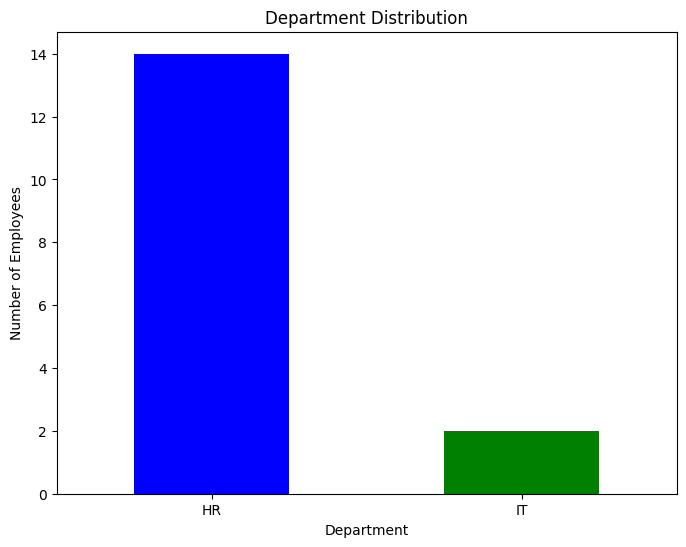

In [19]:
department_counts= data[['Department_hr', 'Department_it']].sum()
department_counts.plot(kind='bar',color=['blue','green'],figsize=(8,6))
plt.title("Department Distribution")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(ticks=[0,1],labels=["HR","IT"], rotation=0)
plt.show()

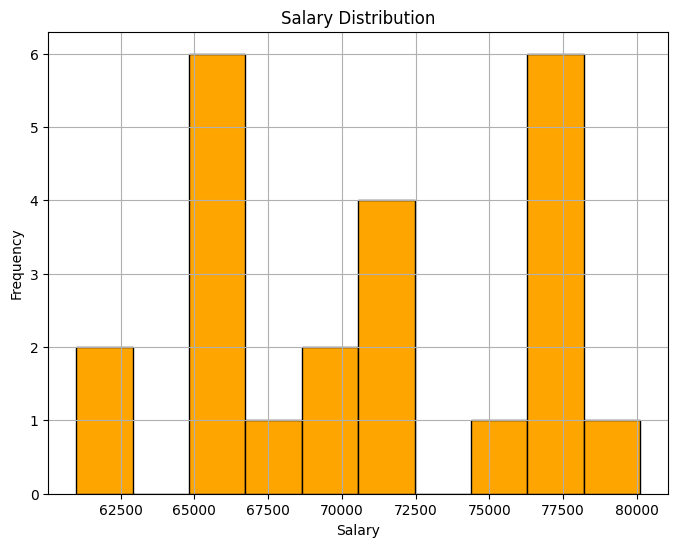

In [20]:
plt.figure(figsize=(8,6))
plt.hist(data['Salary'], bins=10,color='orange',edgecolor='black')
plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

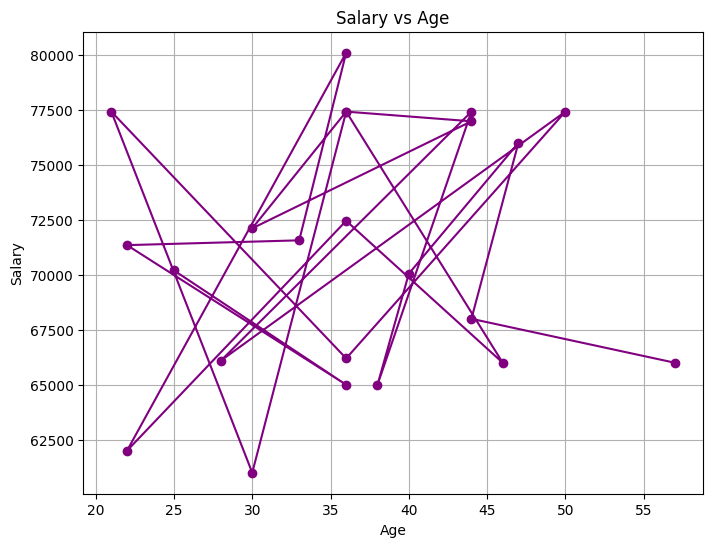

In [21]:
plt.figure(figsize=(8,6))
plt.plot(data['Age'], data['Salary'],marker='o',color='purple',linestyle='-')
plt.title("Salary vs Age")
plt.xlabel("Age")
plt.ylabel("Salary")
plt.grid(True)
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

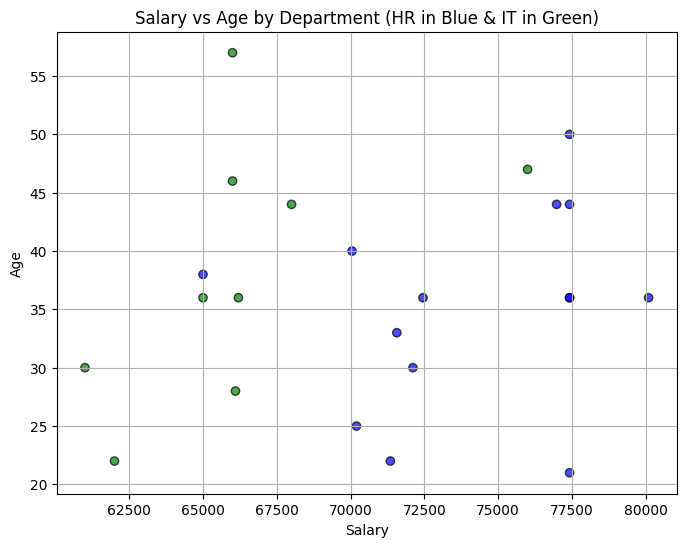

In [23]:
plt.figure(figsize=(8,6))
colors=['blue' if dept==1 else 'green' for dept in data['Department_hr']]
plt.scatter(data['Salary'], data['Age'],c=colors,alpha=0.7,edgecolor='black')
plt.title("Salary vs Age by Department (HR in Blue & IT in Green)")
plt.xlabel("Salary")
plt.ylabel("Age")
plt.grid(True)
plt.show